![Imgur](https://i.imgur.com/A0T6cjl.png)
### [<font size = 2 color="#5890FF">SERIES 3</font>](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents)<font size = 2 color="#7B8698">　‣　D A T A　E X P L O R A T I O N　🔭<br></font>[Introduction](https://www.kaggle.com/code/samybaladram/03-1-data-exploration-introduction)・[Summary Statistics](https://www.kaggle.com/code/samybaladram/03-2-data-exploration-summary-statistics)・**Distribution Types**・[Distribution Fitting](https://www.kaggle.com/code/samybaladram/03-4-data-exploration-distribution-fitting)・[Bivariate Analysis](https://www.kaggle.com/code/samybaladram/03-5-data-exploration-bivariate-analysis)<p>
---

# Measures of **Distribution**
![Imgur](https://i.imgur.com/rQwEUqD.png)

# Benefits of Knowing Distribution
![Imgur](https://i.imgur.com/UPnekDt.png)

# 📊　Dataset & Libraries Used
![Imgur](https://i.imgur.com/s1A2Hac.png)

In [ ]:
# All codes depend on this cell
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 300
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["figure.figsize"] = (4.5, 3.5)

golf_dataset = pd.read_csv("./Data/golf_dataset_weather_tropical_1year.csv")
df = golf_dataset[['Date','Outlook'] + golf_dataset.select_dtypes(include=['number']).columns.tolist()].copy()

df

,Date,Outlook,SunshineDuration,Temperature,Humidity,WindDirection,WindSpeed,Pressure,TotalPlayer,TimePerRound
0,2021-01-01,rainy,1.7,27.2,79,62.0,1.3,1010.3,28,206
1,2021-01-02,sunny,11.8,33.4,70,350.0,0.1,1013.2,74,453
2,2021-01-03,sunny,13.1,31.3,75,345.3,2.2,1005.5,63,290
3,2021-01-04,overcast,0.8,26.8,68,304.2,2.3,1009.6,56,298
4,2021-01-05,sunny,5.1,30.8,59,0.1,6.2,1011.3,70,213
...,...,...,...,...,...,...,...,...,...,...
360,2021-12-27,rainy,2.8,25.0,85,318.9,0.4,1008.1,30,346
361,2021-12-28,rainy,0.3,22.3,71,327.8,0.7,1013.7,26,265
362,2021-12-29,sunny,5.7,29.7,65,343.6,1.9,1010.6,80,442
363,2021-12-30,overcast,4.8,26.8,84,0.6,0.6,1007.5,60,342


# 　Histogram
![Imgur](https://i.imgur.com/WsacBo8.png)
![Imgur](https://i.imgur.com/76Fadxh.png)
![Imgur](https://i.imgur.com/XSDMGcJ.png)
![Imgur](https://i.imgur.com/PvPl51F.png)

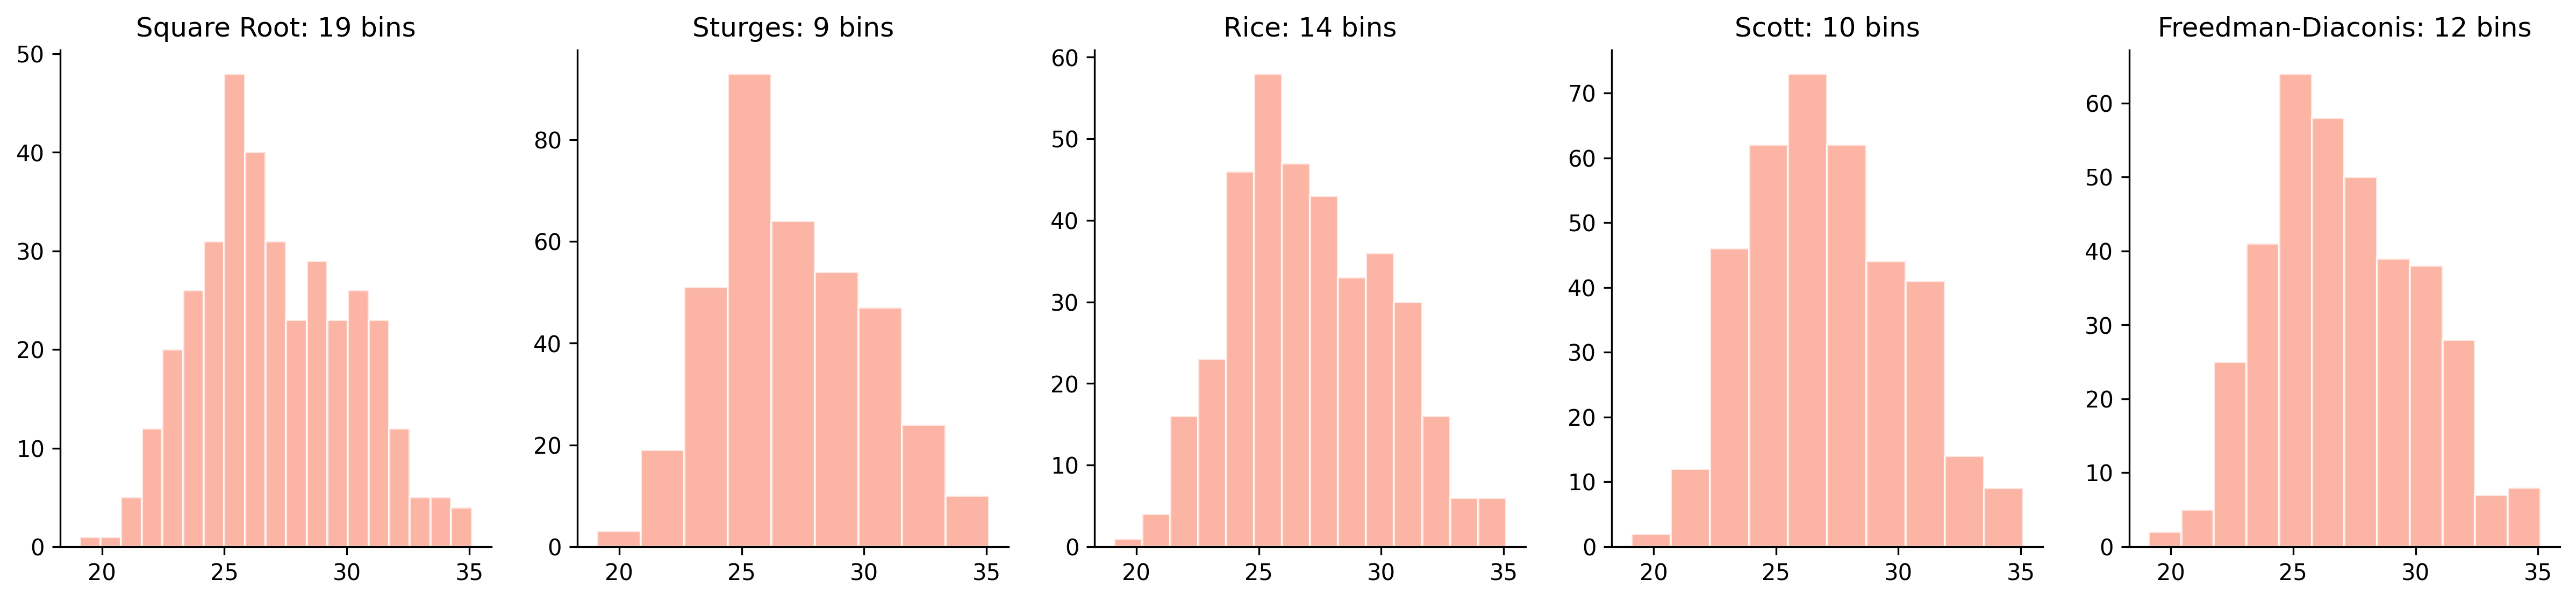

In [2]:
temp_data = df['Temperature']

# Calculate variables
n = len(temp_data)
std_dev = np.std(temp_data)
IQR = np.percentile(temp_data, 75) - np.percentile(temp_data, 25)

# Calculate bins
bins_dict = {
    "Square Root": int(np.sqrt(n)),
    "Sturges": int(1 + 3.322 * np.log10(n)),
    "Rice": int(2 * n ** (1/3)),
    "Scott": int((max(temp_data) - min(temp_data)) / (3.5 * std_dev / n ** (1/3))),
    "Freedman-Diaconis": int((max(temp_data) - min(temp_data)) / (2 * IQR / n ** (1/3)))
}

# Create the subplots
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# Plot histograms
for i, (title, bins) in enumerate(bins_dict.items()):
    axes[i].hist(temp_data, bins=bins, edgecolor='white', color="#FB967F", alpha=0.7)
    axes[i].set_title(f"{title}: {bins} bins")

plt.show()

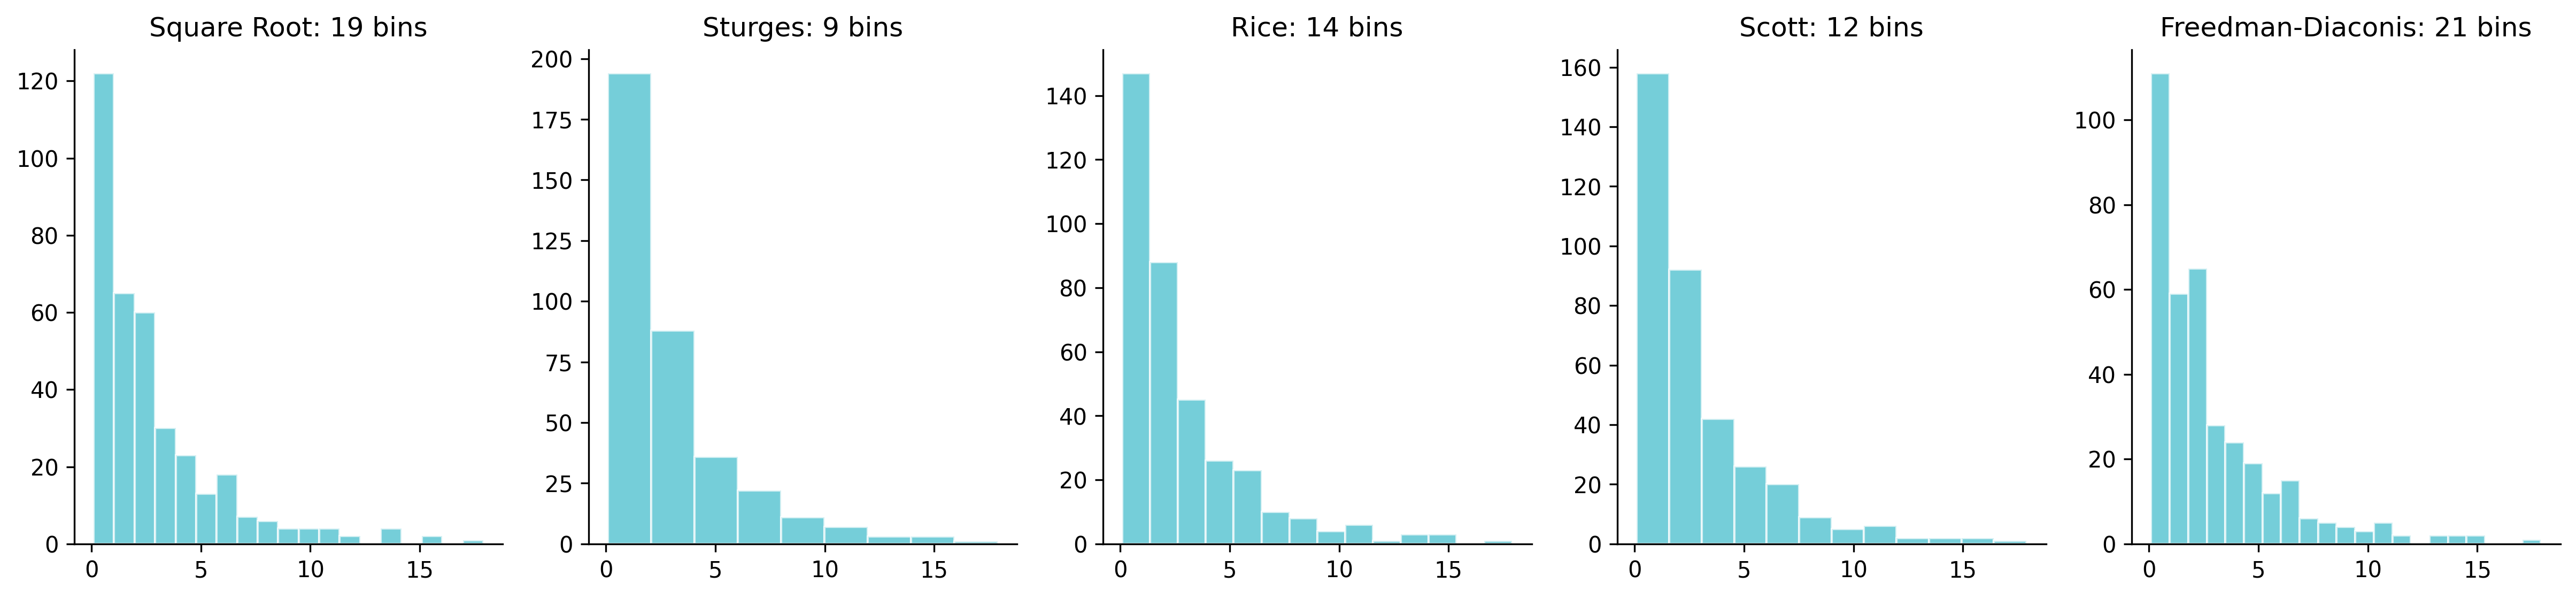

In [3]:
temp_data = df['WindSpeed']

# Calculate variables
n = len(temp_data)
std_dev = np.std(temp_data)
IQR = np.percentile(temp_data, 75) - np.percentile(temp_data, 25)

# Calculate bins
bins_dict = {
    "Square Root": int(np.sqrt(n)),
    "Sturges": int(1 + 3.322 * np.log10(n)),
    "Rice": int(2 * n ** (1/3)),
    "Scott": int((max(temp_data) - min(temp_data)) / (3.5 * std_dev / n ** (1/3))),
    "Freedman-Diaconis": int((max(temp_data) - min(temp_data)) / (2 * IQR / n ** (1/3)))
}

# Create the subplots
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# Plot histograms
for i, (title, bins) in enumerate(bins_dict.items()):
    axes[i].hist(temp_data, bins=bins, edgecolor='white', color="#3BBAC9", alpha=0.7)
    axes[i].set_title(f"{title}: {bins} bins")

plt.show()

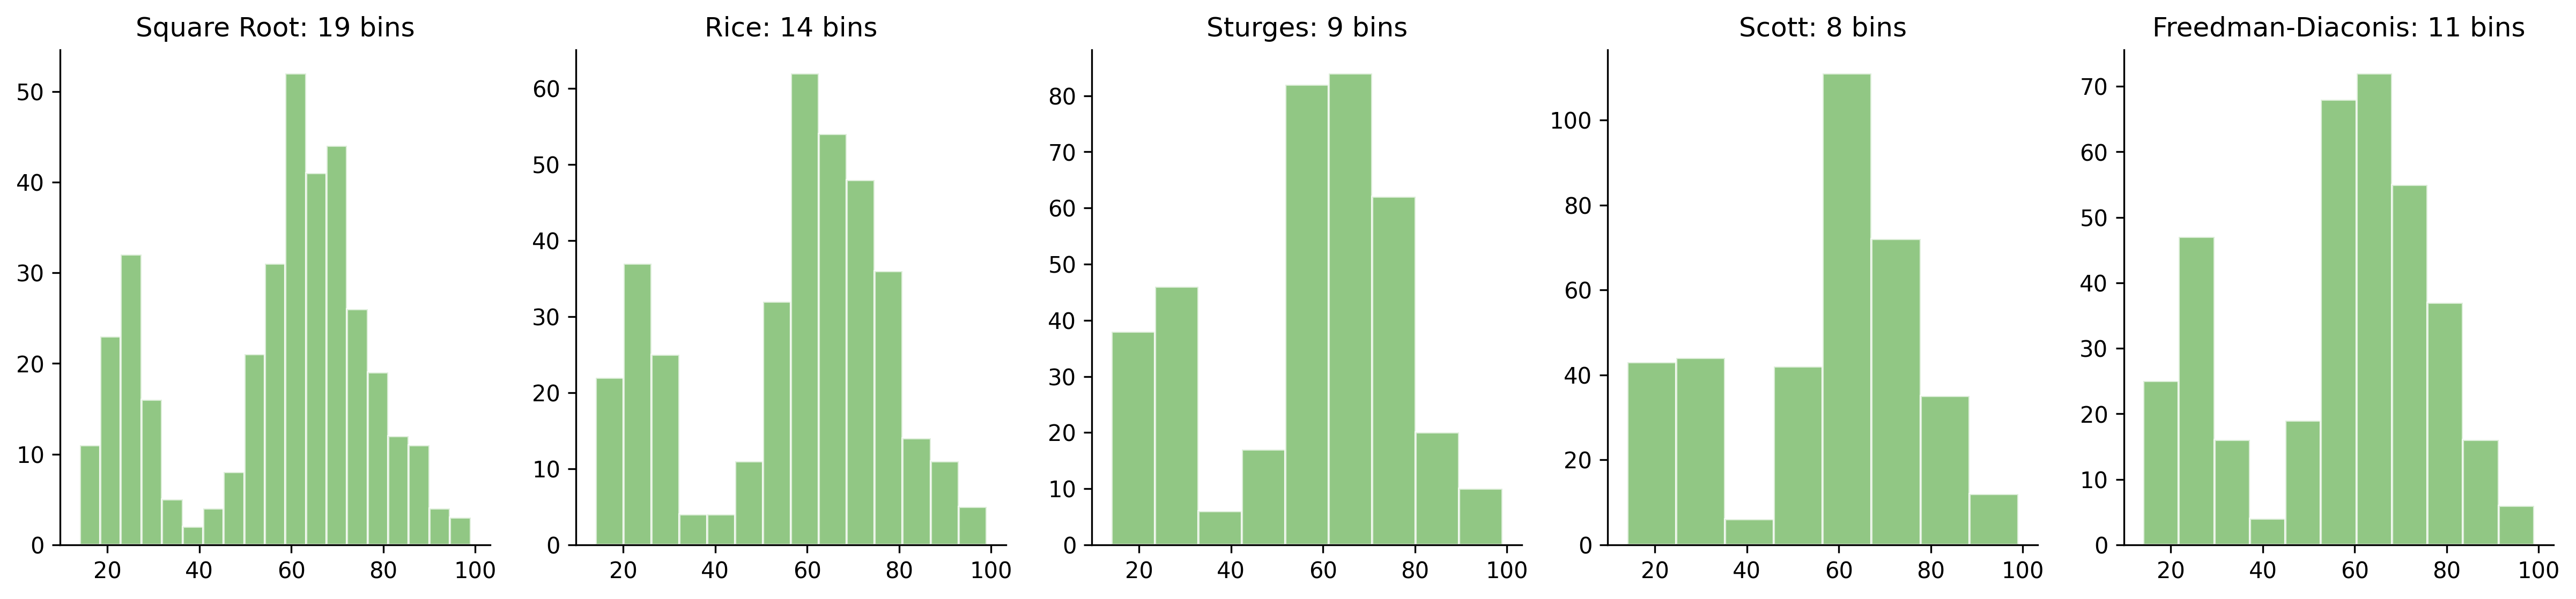

In [4]:
temp_data = df['TotalPlayer']

# Calculate variables
n = len(temp_data)
std_dev = np.std(temp_data)
IQR = np.percentile(temp_data, 75) - np.percentile(temp_data, 25)
range_data = max(temp_data) - min(temp_data)
n_root = n ** (1/3)

# Calculate bins and combine with titles in a dictionary
bins_dict = {
    "Square Root": int(np.sqrt(n)),
    "Rice": int(2 * n_root),
    "Sturges": int(1 + 3.322 * np.log10(n)),
    "Scott": int(range_data / (3.5 * std_dev / n_root)),
    "Freedman-Diaconis": int(range_data / (2 * IQR / n_root))
}

# Create the subplots
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# Plot histograms
for i, (title, bins) in enumerate(bins_dict.items()):
    axes[i].hist(temp_data, bins=bins, edgecolor='white', color="#62B050", alpha=0.7)
    axes[i].set_title(f"{title}: {bins} bins")

plt.show()

# 　Density Plot
![Imgur](https://i.imgur.com/An0J9bP.png)
![Imgur](https://i.imgur.com/VUpEYhr.png)

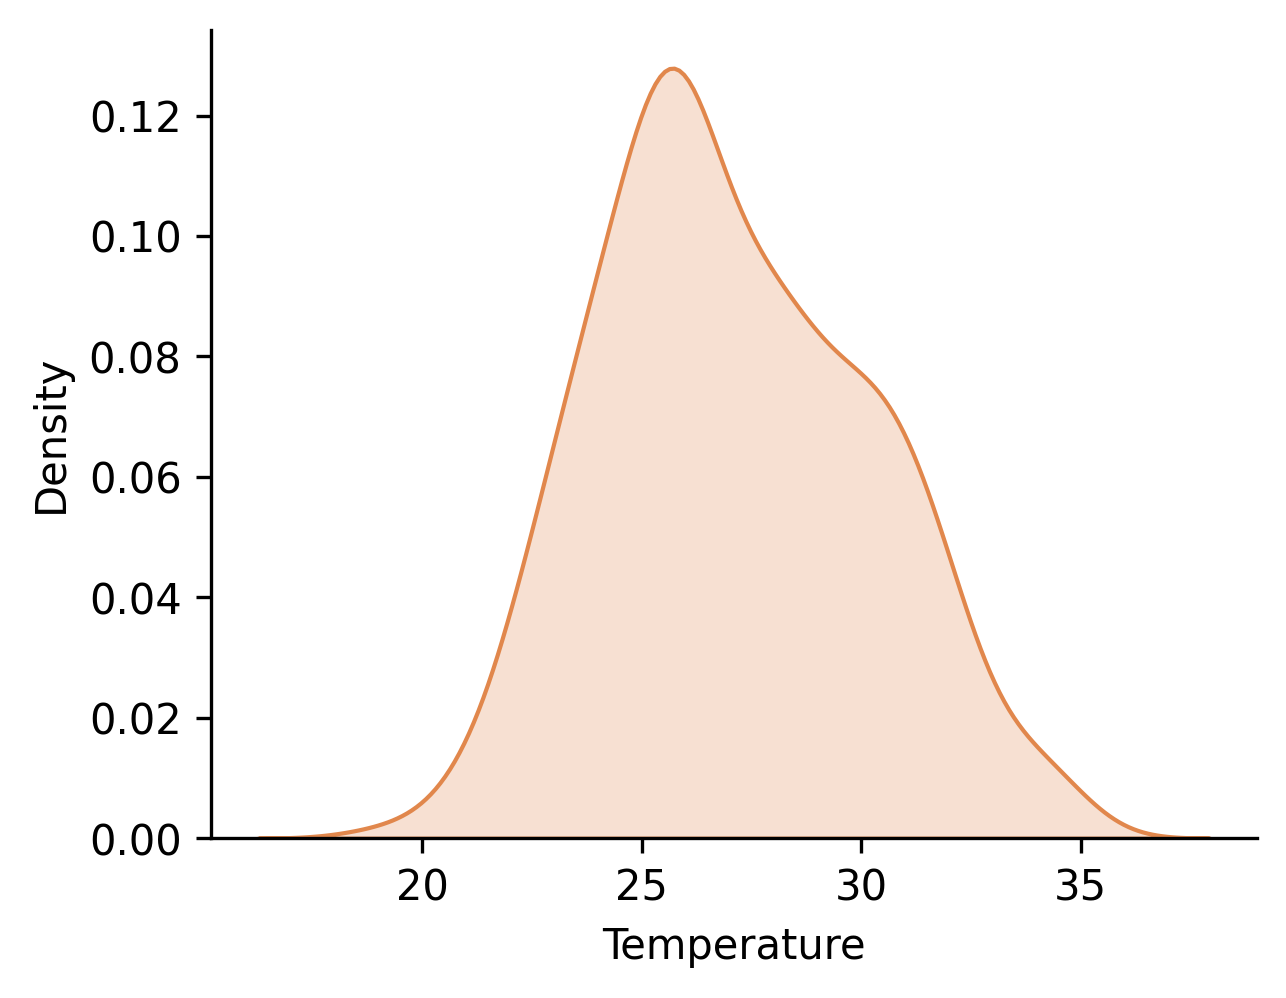

In [5]:
sns.kdeplot(df['Temperature'], fill=True, color="#E1874C")
plt.show()

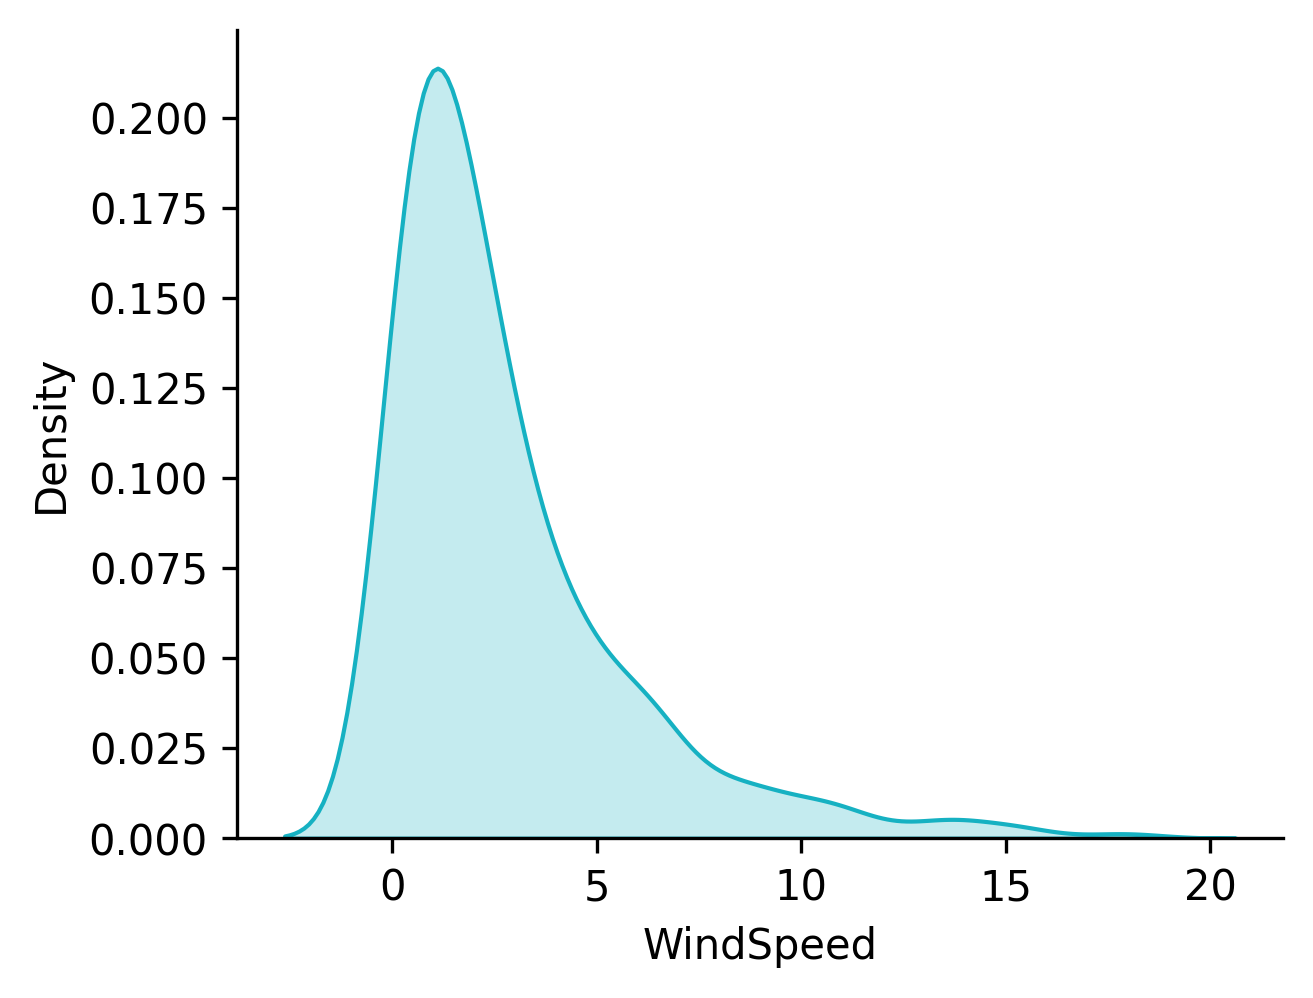

In [6]:
sns.kdeplot(df['WindSpeed'], fill=True, color="#16B1C2")
plt.show()

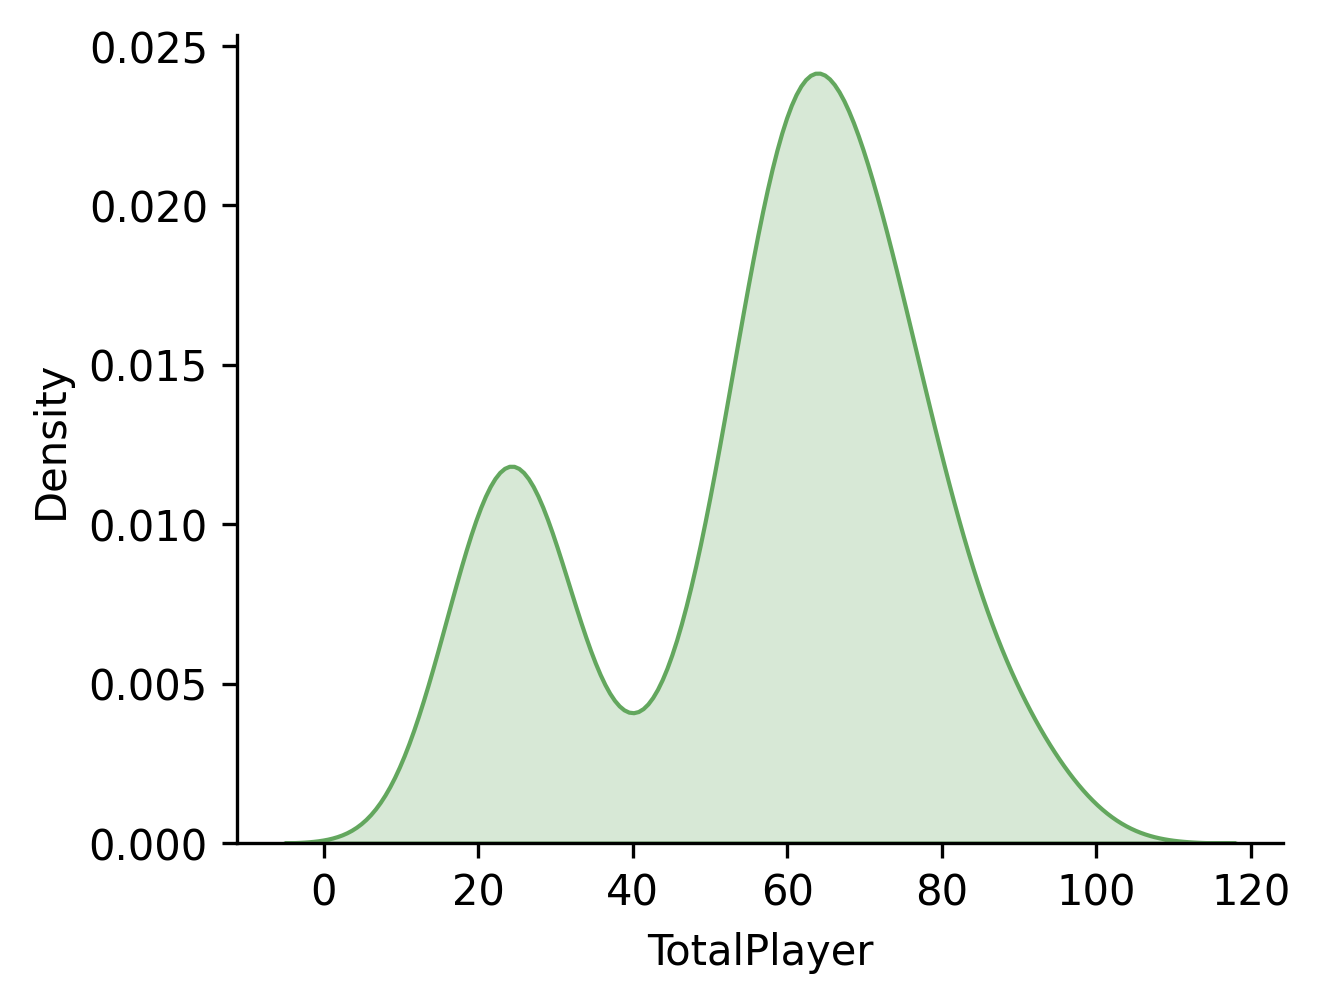

In [7]:
sns.kdeplot(df['TotalPlayer'], fill=True, color="#63A75E")
plt.show()

# Types of Distribution
![Imgur](https://i.imgur.com/xccyDZb.png)

# 　Normal Distribution
![Imgur](https://i.imgur.com/vPt3IlO.png)
![Imgur](https://i.imgur.com/xAi4WXa.png)

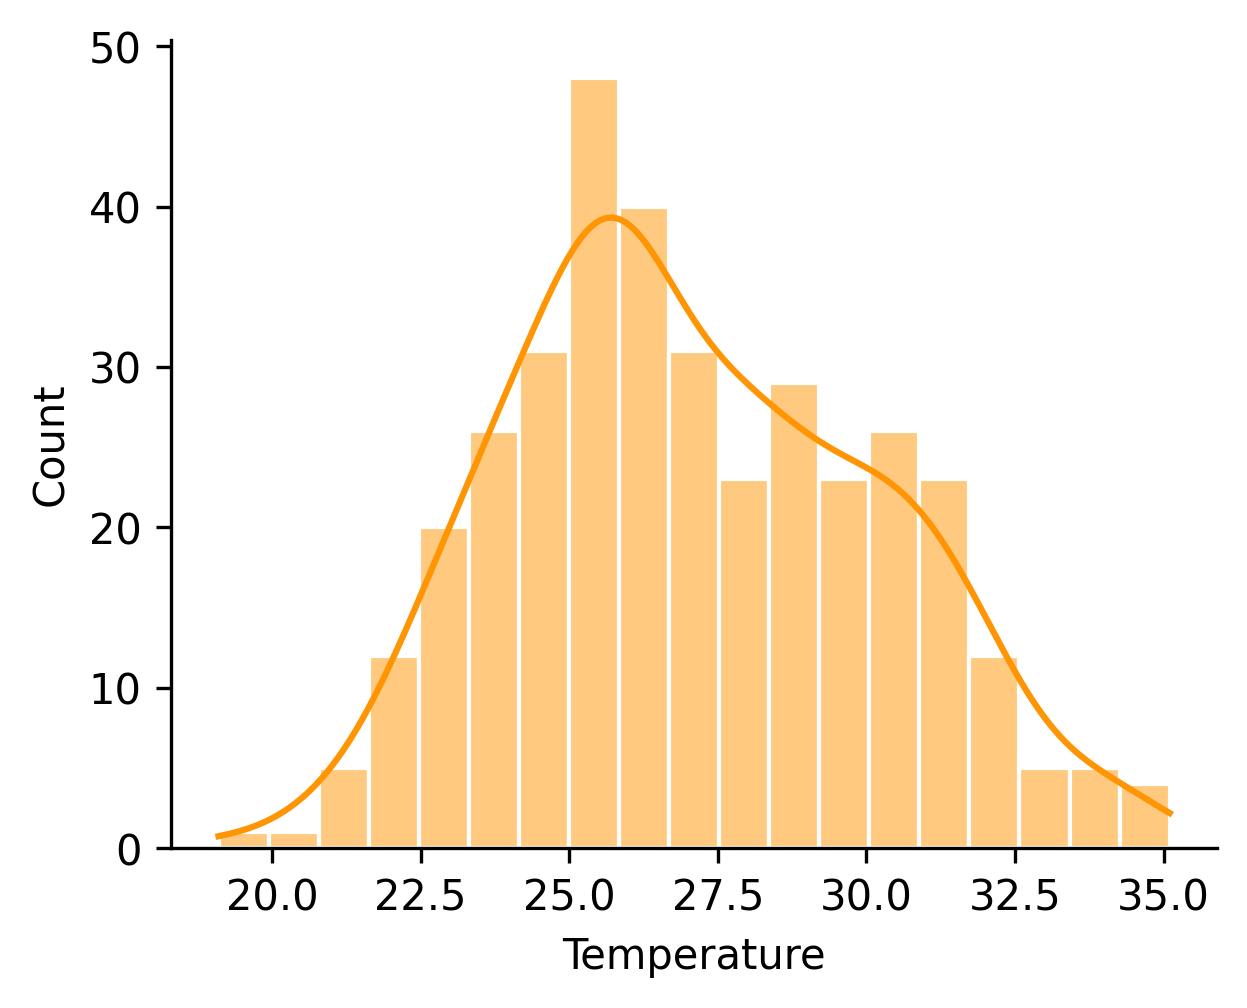

In [8]:
sns.histplot(df['Temperature'], bins=19, edgecolor='white', kde=True, color="#FF9502")
plt.show()

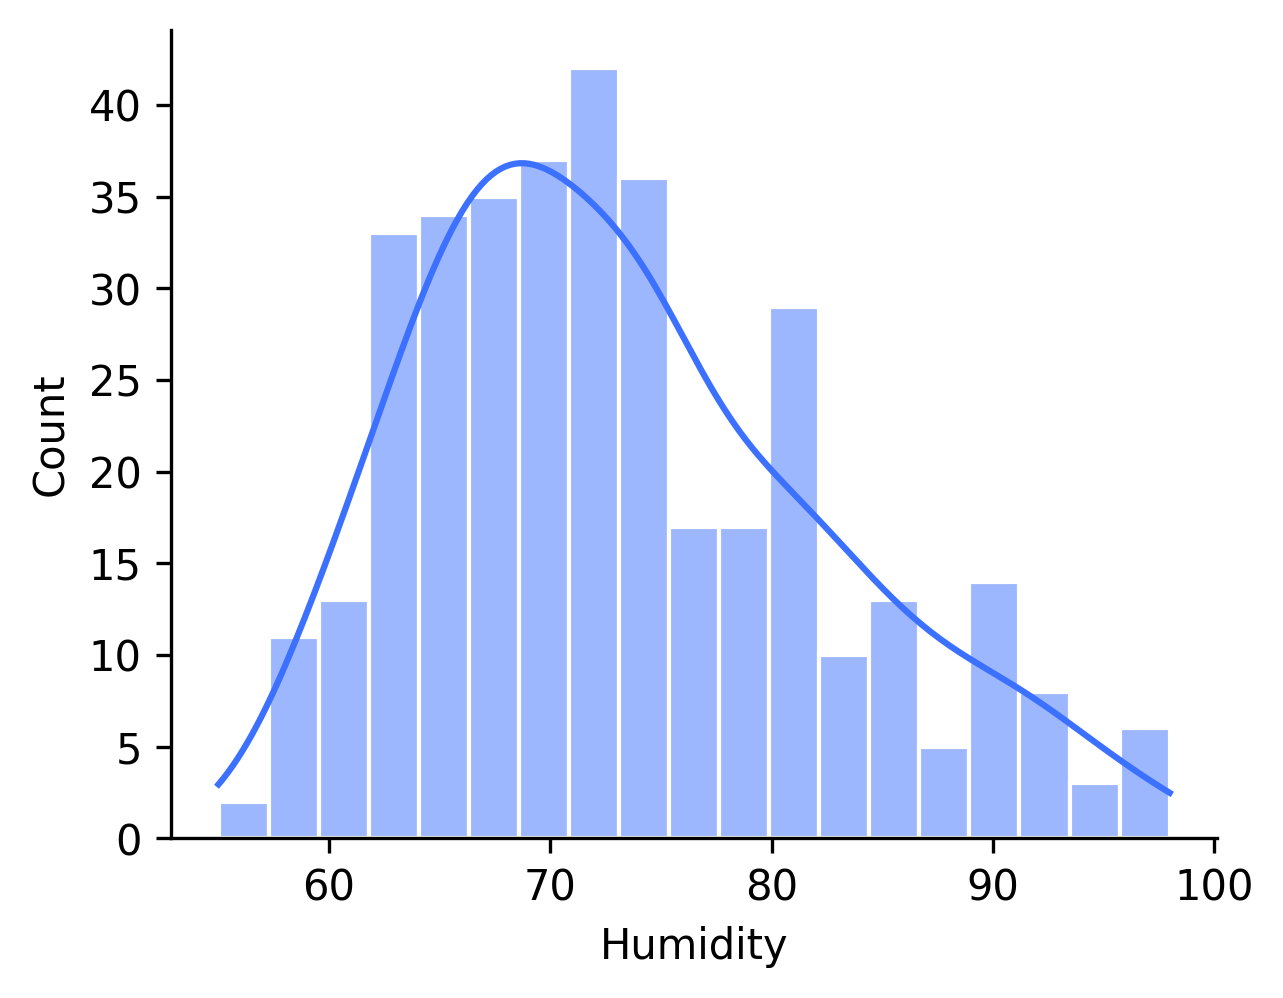

In [9]:
sns.histplot(df['Humidity'], bins=19, kde=True, edgecolor="white", color="#3C70FF")
plt.show()

# 　Log-Normal Distribution
![Imgur](https://i.imgur.com/nY14c79.png)
![Imgur](https://i.imgur.com/zkauqO4.png)

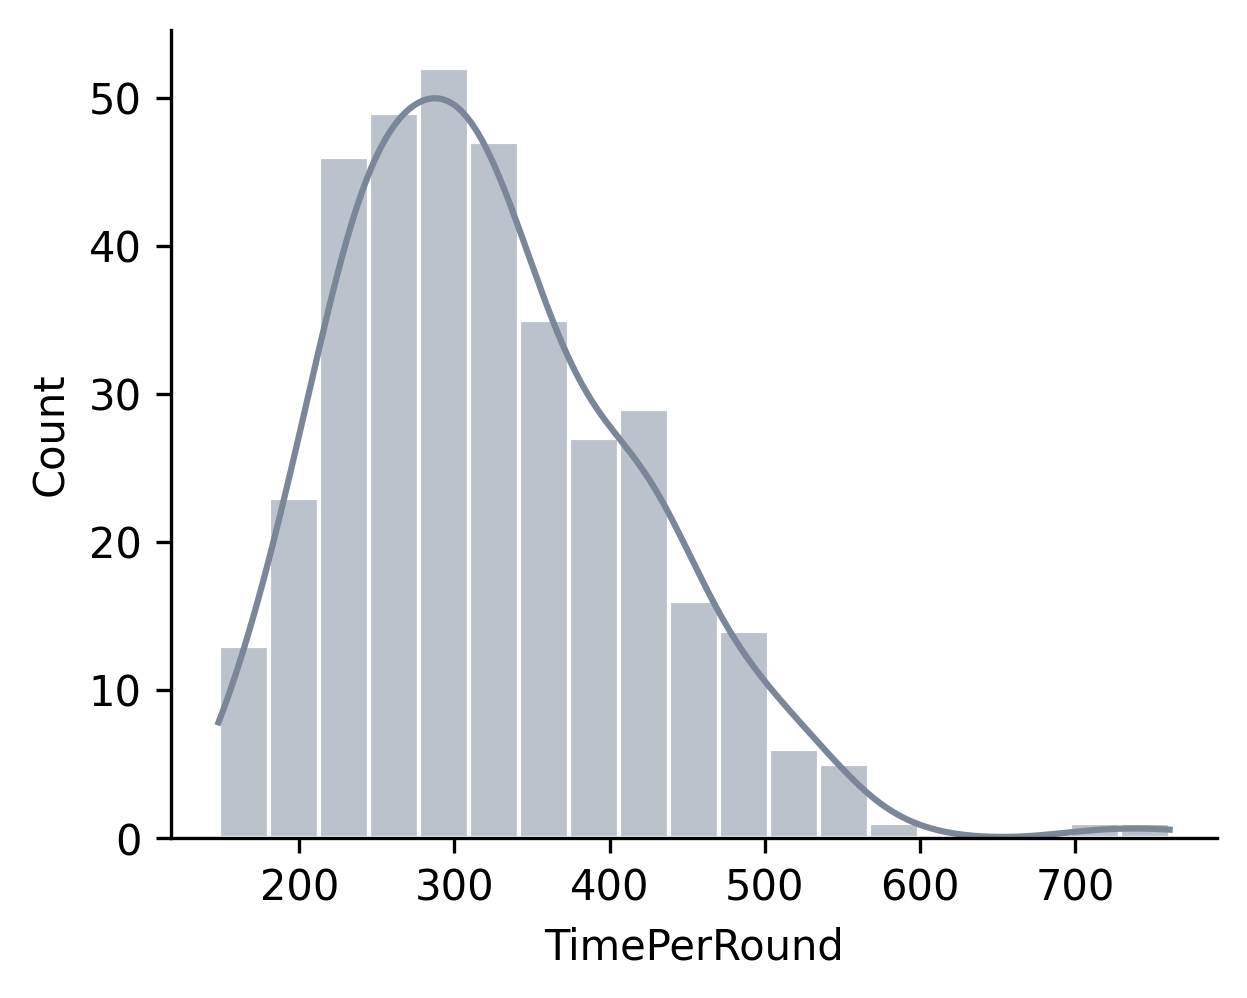

In [10]:
sns.histplot(df['TimePerRound'], bins=19, kde=True, edgecolor="white", color="#7B8699")
plt.show()

# 　Exponential Distribution
![Imgur](https://i.imgur.com/PY4mgle.png)
![Imgur](https://i.imgur.com/Z5maUj9.png)

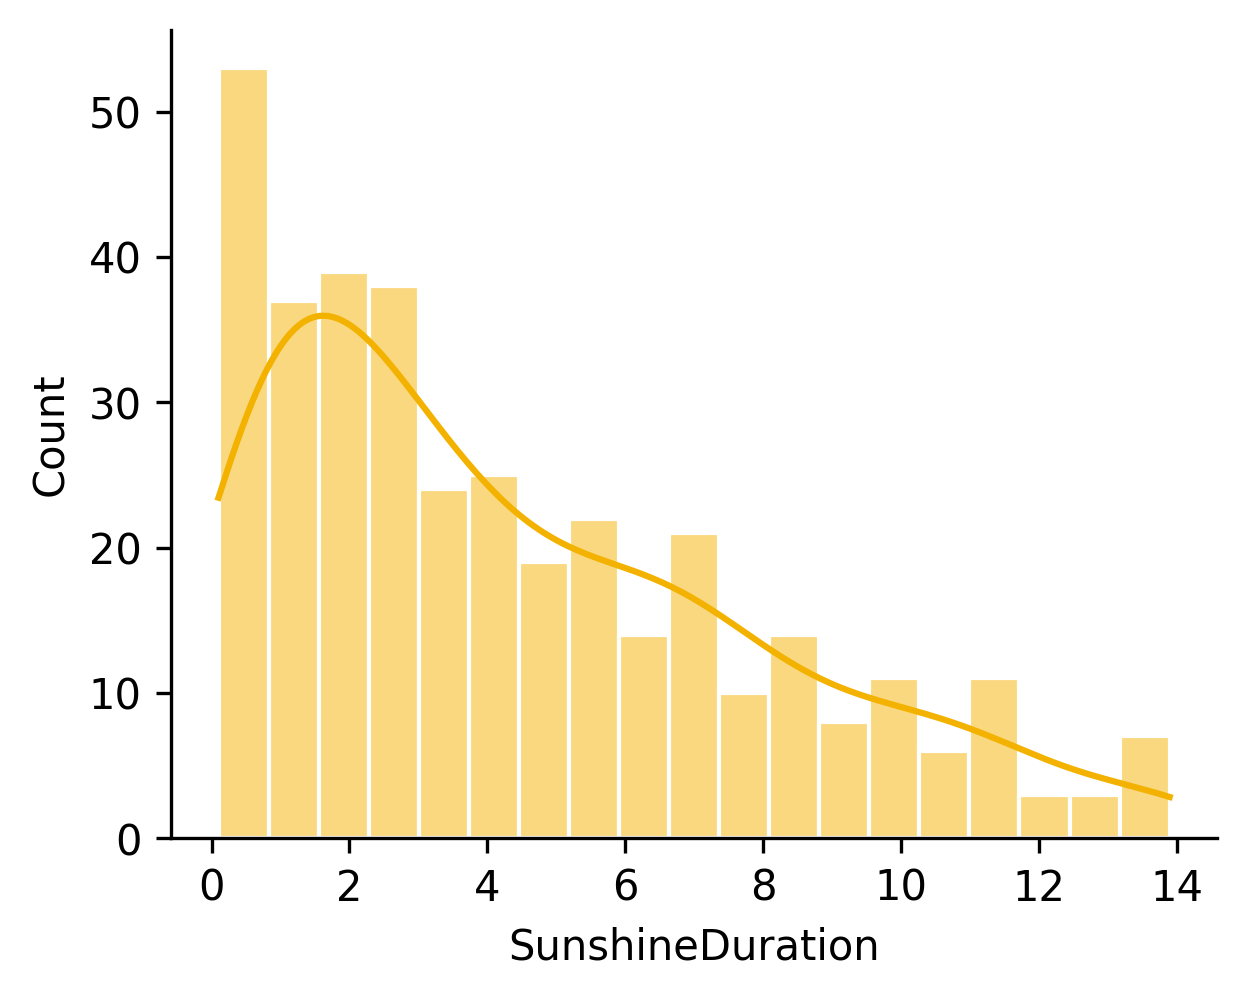

In [11]:
sns.histplot(df['SunshineDuration'], bins=19, kde=True, color="#f4b200", edgecolor="white")
plt.show()

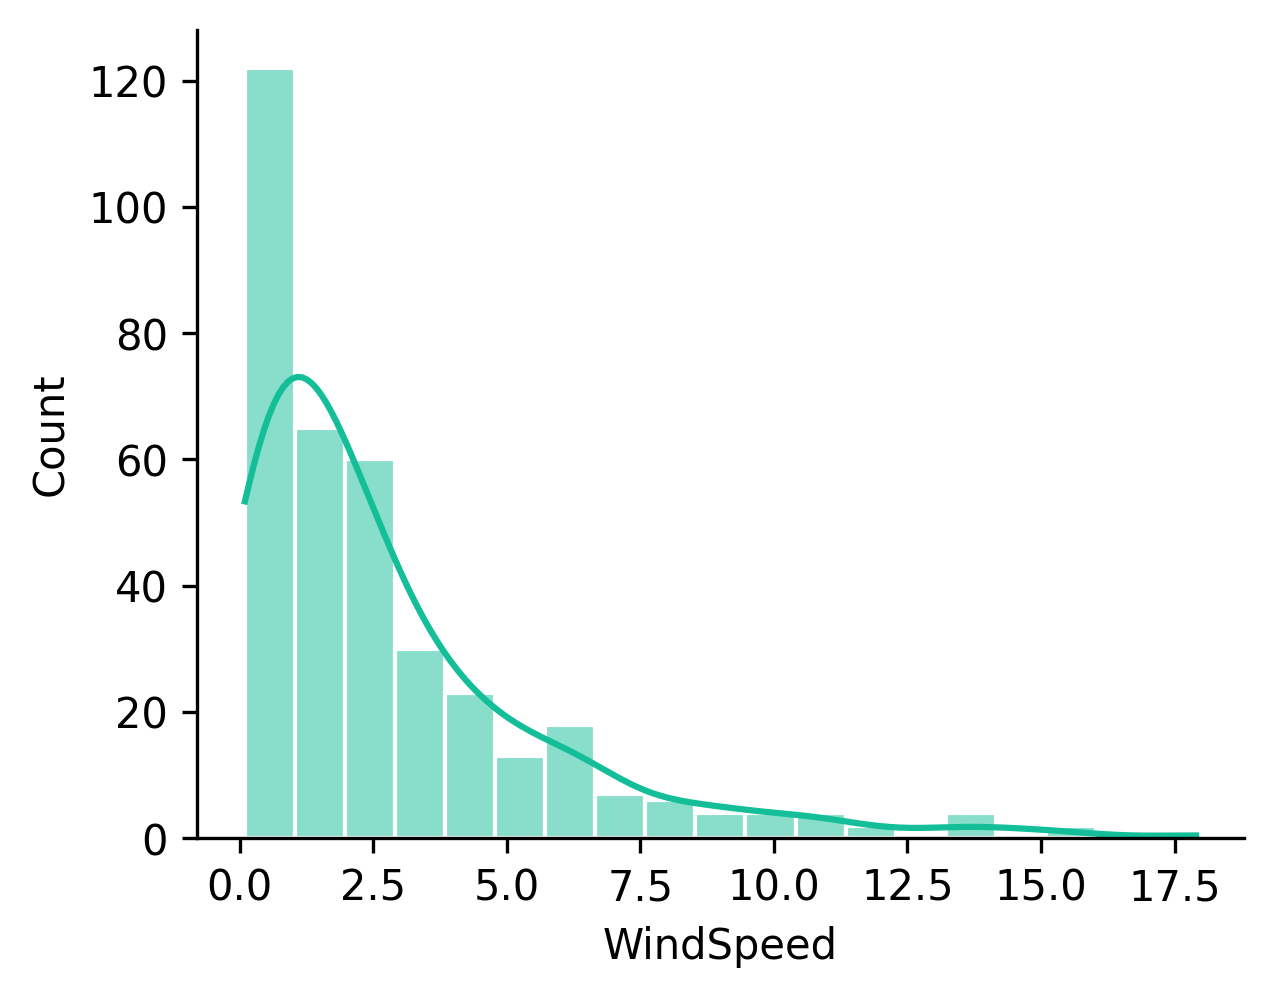

In [12]:
sns.histplot(df['WindSpeed'], bins=19, kde=True, color="#13be99", edgecolor="white")
plt.show()


# 　Poisson Distribution
![Imgur](https://i.imgur.com/g8xoDwE.png)
![Imgur](https://i.imgur.com/PHQrhIS.png)

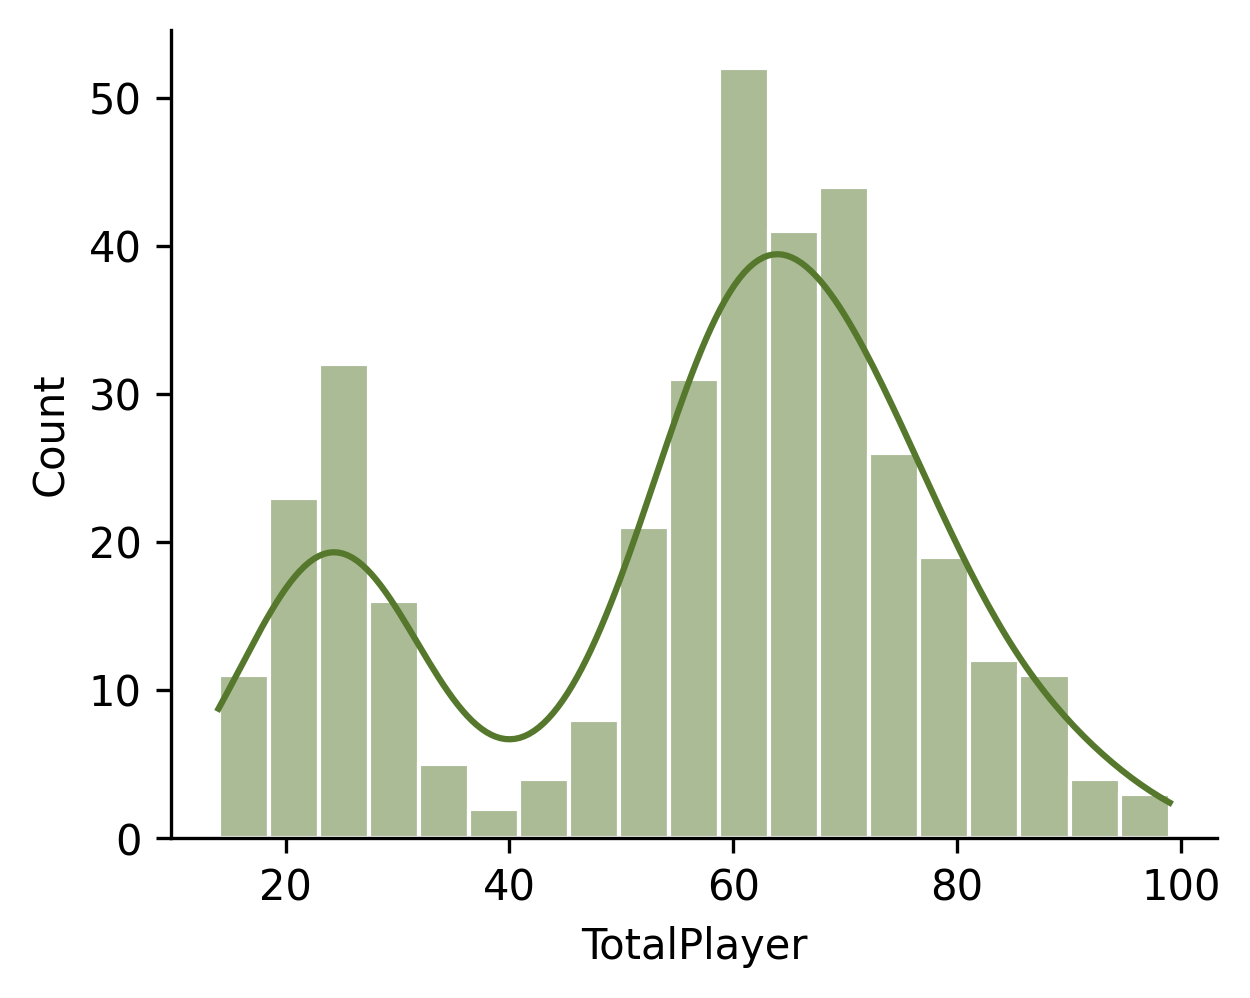

In [13]:
sns.histplot(df['TotalPlayer'], bins=19, kde=True, color= "#56782D", edgecolor="white")
plt.show()

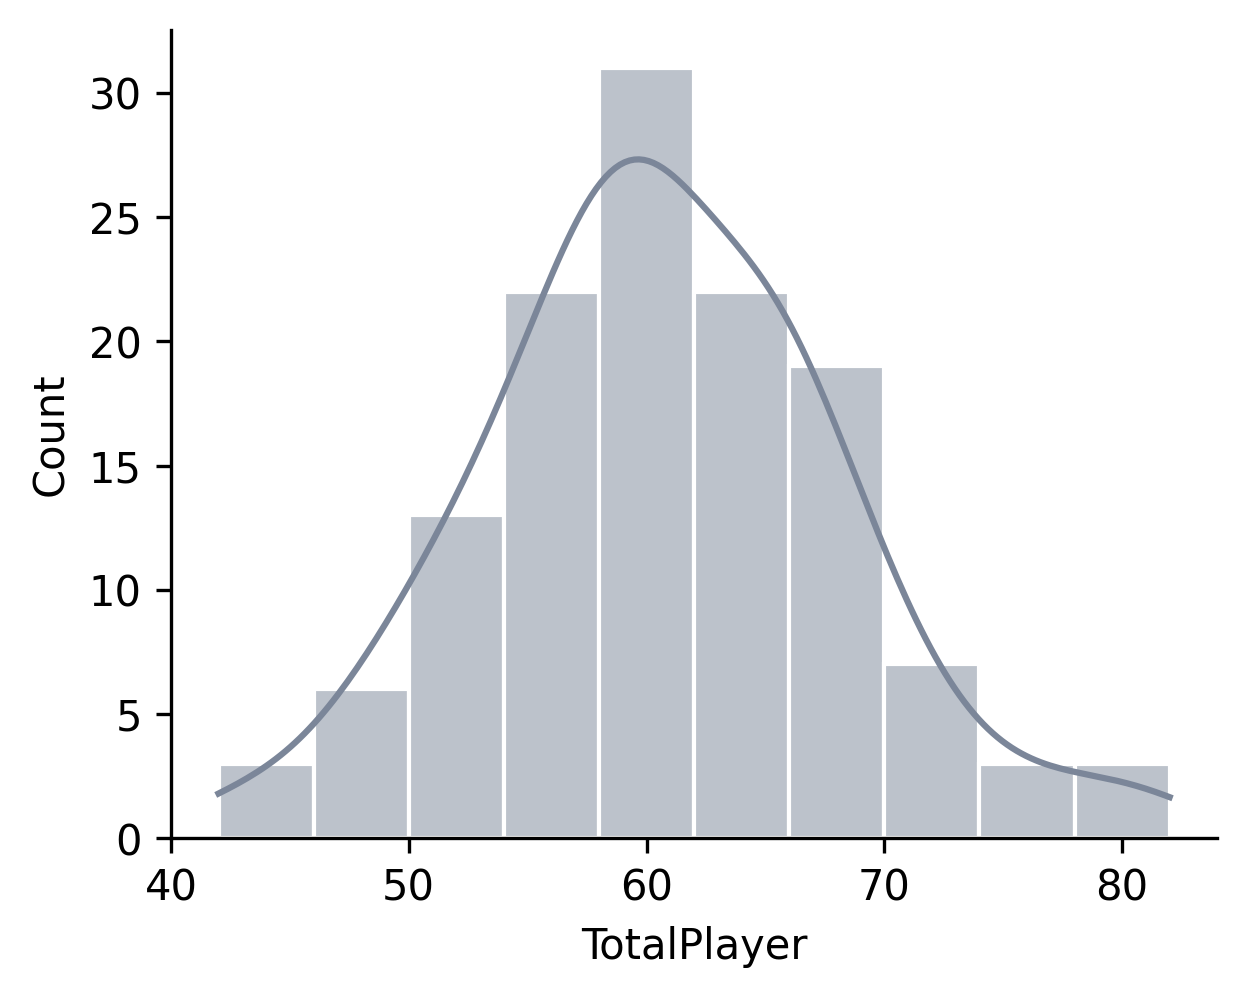

In [14]:
sns.histplot(df[df['Outlook'] == 'overcast']['TotalPlayer'], bins=10, kde=True, color="#7B8699", edgecolor="white")
plt.show()

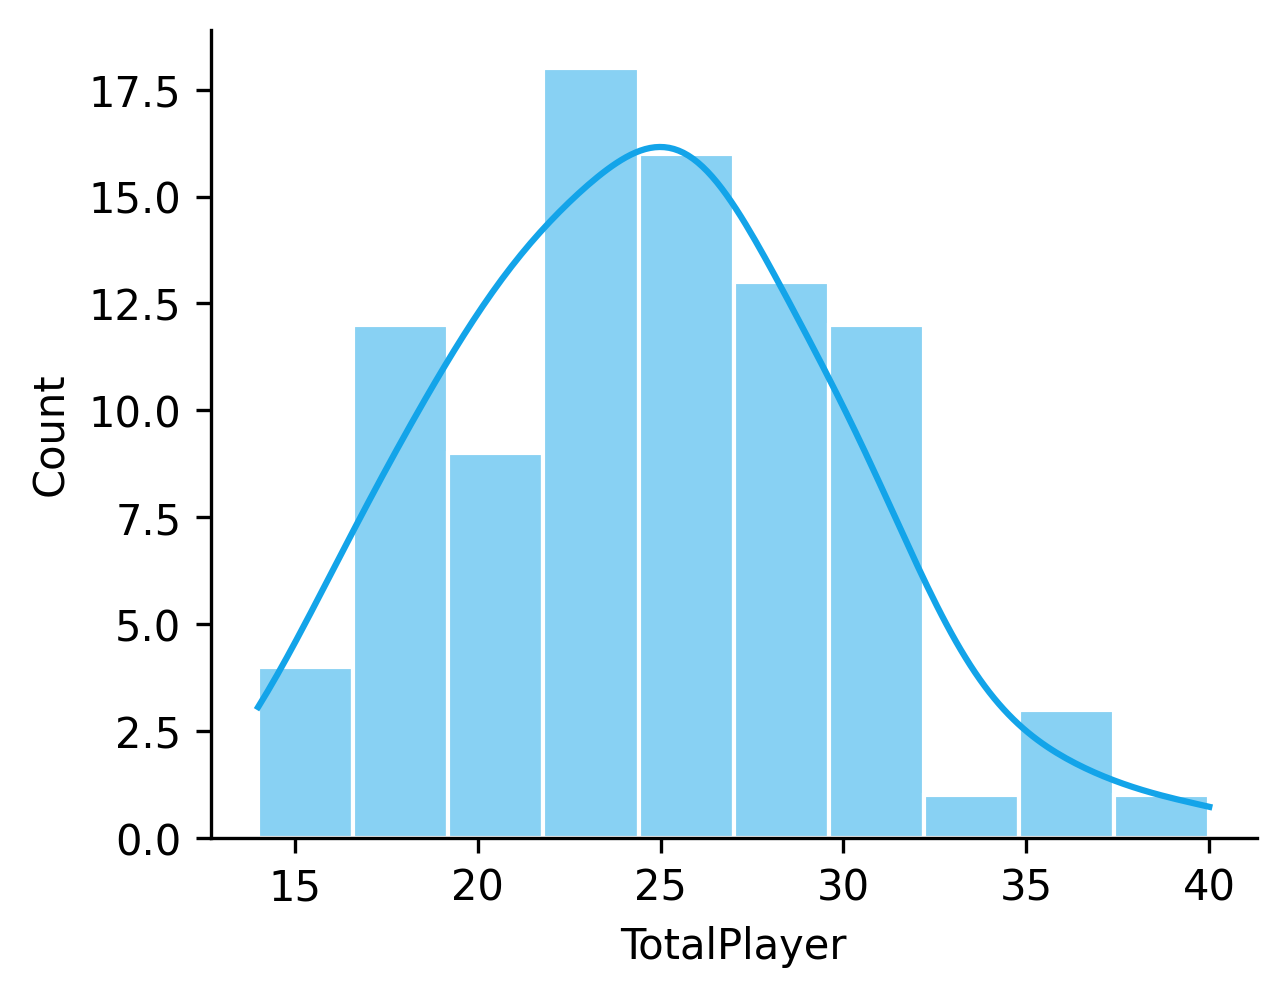

In [15]:
sns.histplot(df[df['Outlook'] == 'rainy']['TotalPlayer'], bins=10, kde=True, color="#13a4e9", edgecolor="white")
plt.show()

# 　Binomial Distribution
![Imgur](https://i.imgur.com/qk2WiL4.png)

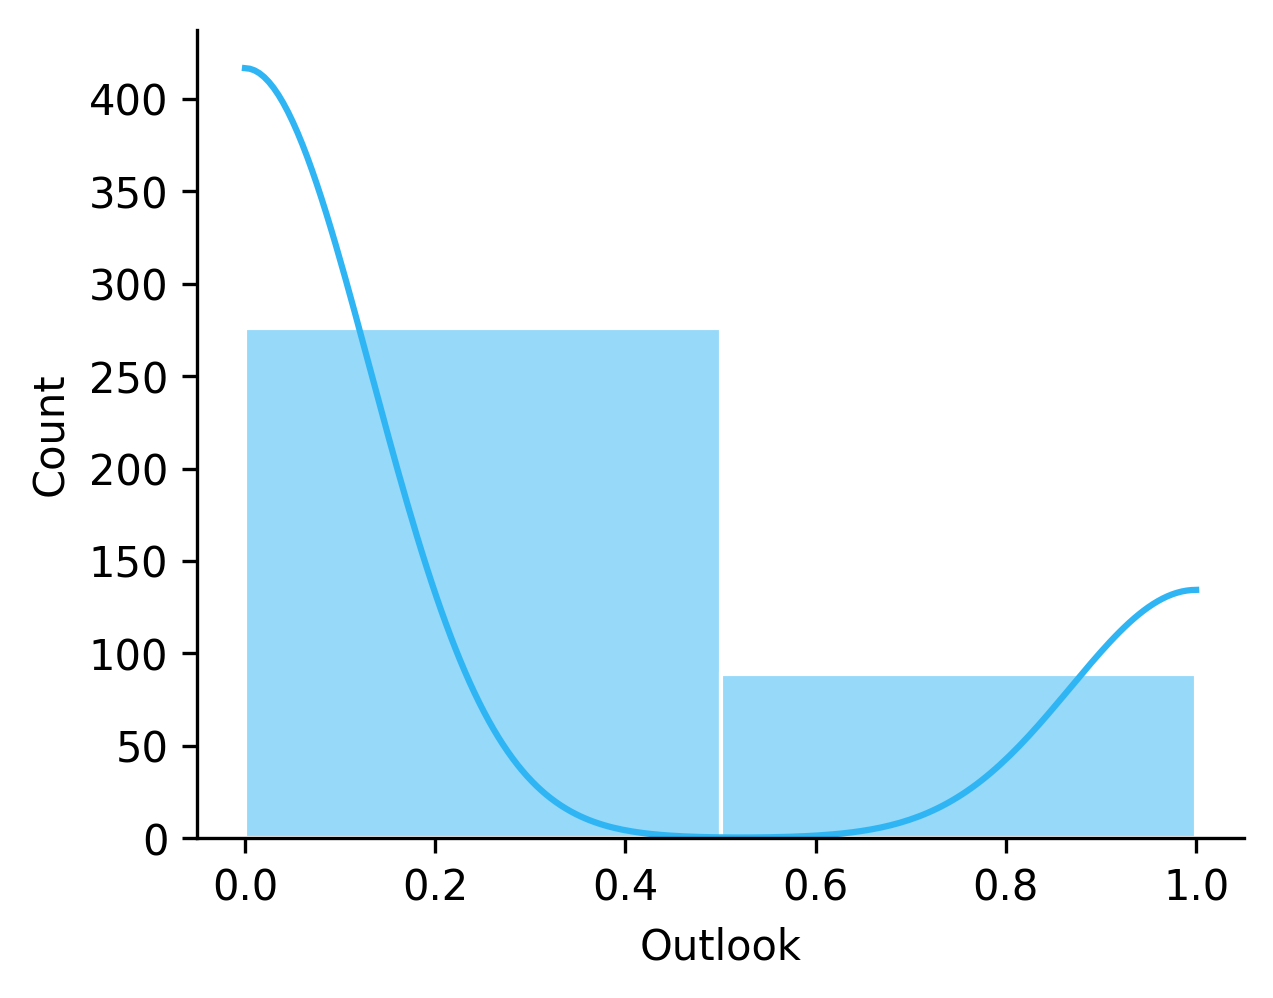

In [16]:
sns.histplot((df['Outlook'] == 'rainy').astype(int), bins=2, kde=True, color="#2FB5F4", edgecolor="white")
plt.show()

# 　Uniform Distribution
![Imgur](https://i.imgur.com/TgiEOnW.png)
![Imgur](https://i.imgur.com/9pjdJ8b.png)

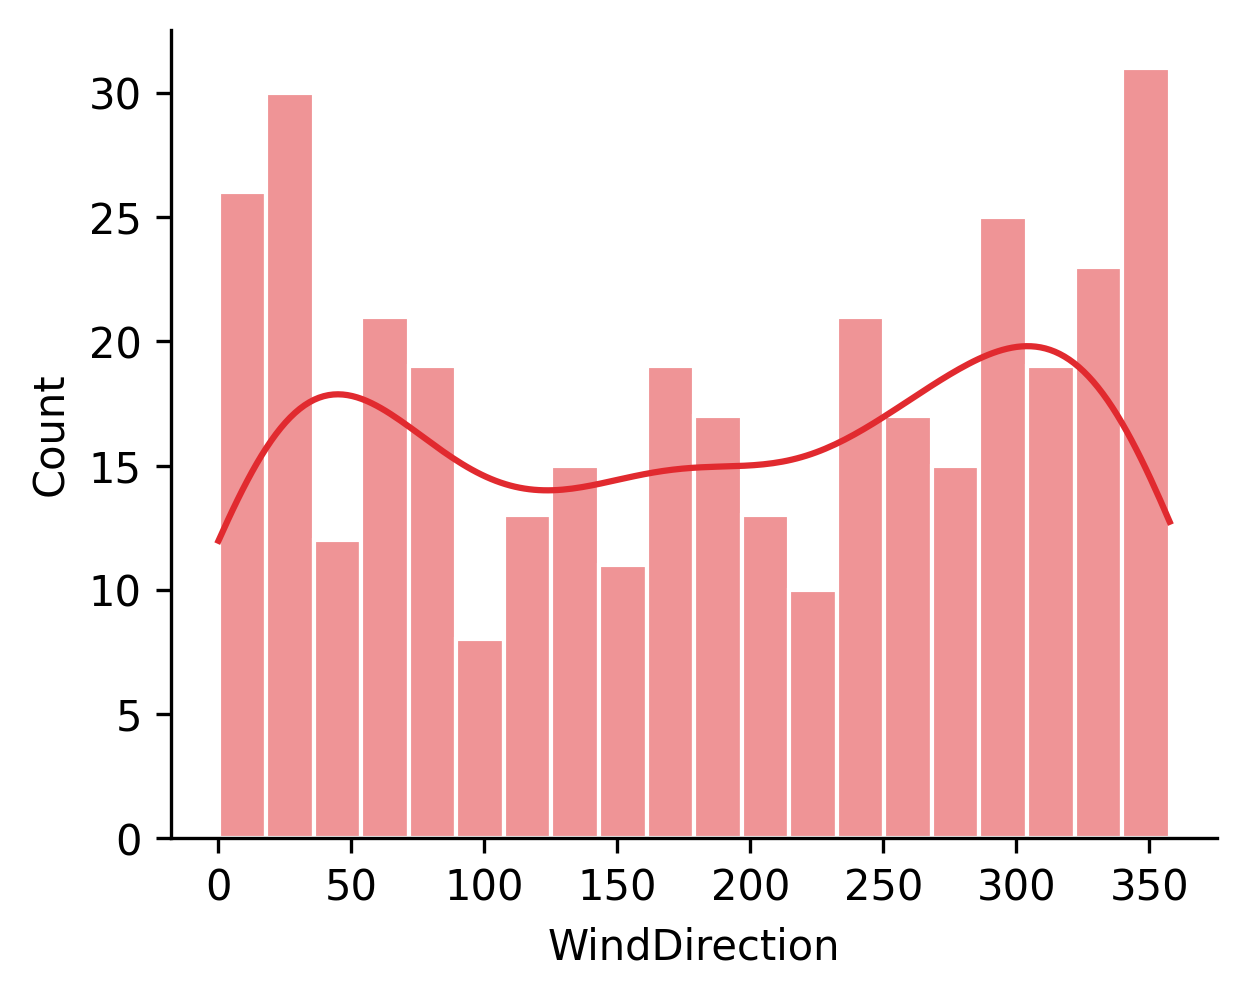

In [17]:
sns.histplot(df['WindDirection'], bins=20, kde=True, color="#E12A2F", edgecolor="white")
plt.show()

![Imgur](https://i.imgur.com/b7WBMDk.png)

![Imgur](https://i.imgur.com/rhybfvB.png)

![Imgur](https://i.imgur.com/M0mwv0l.png)

--- 

*Explore [diverse notebooks full of captivating visuals](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents), each tackling unique facets of the field—all based on some mini, yet enriching, golf play datasets. Your hole-in-one guide to mastering Data Science basics.*


### For a complete list of topics and series, see [⛳️ 📋 Data Science with Golf Dataset・Table of Contents](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents).
---

**Your Feedback Matters! 🍃** If you find this notebook series useful, an ⬆️ *upvote* would be appreciated to help others in the community discover it too!

───────────────
　

**Your Feedback Matters!** 🍃

If you find this notebook useful for your projects or learning, an ⬆️ **upvote** would be appreciated to help others in the community discover it too! (and it's free!)
